In [59]:
import pandas as pd
import numpy as np
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

df = pd.read_csv('cars.csv')

In [60]:
df.head()

,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city,brand_rank,car_age
0,0,2016,Honda,Honda Brio S MT,Brio,425000.0,9680.0,Petrol,Mumbai,7,5.0
1,1,2012,Nissan,Nissan Sunny XV Diesel,Sunny,325000.0,119120.0,Diesel,Mumbai,11,9.0
2,2,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2650000.0,64593.0,Diesel,Thane,1,4.0
3,3,2017,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,4195000.0,25000.0,Diesel,Mumbai,2,4.0
4,4,2012,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,475000.0,23800.0,Diesel,Mumbai,14,9.0


In [61]:
df.describe()

,Id,year,price,distance_travelled(kms),brand_rank,car_age
count,1725.000000,1725.000000,1.725000e+03,1725.000000,1725.000000,1725.000000
mean,862.000000,2015.390725,1.494837e+06,53848.256232,15.731014,5.609275
std,498.108924,3.207504,1.671658e+06,44725.541963,12.951122,3.207504
min,0.000000,1990.000000,6.250000e+04,350.000000,1.000000,0.000000
25%,431.000000,2013.000000,5.450000e+05,29000.000000,5.000000,3.000000
50%,862.000000,2016.000000,8.750000e+05,49000.000000,14.000000,5.000000
75%,1293.000000,2018.000000,1.825000e+06,70500.000000,24.000000,8.000000
max,1724.000000,2021.000000,1.470000e+07,790000.000000,81.000000,31.000000


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1725 entries, 0 to 1724
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Id                       1725 non-null   int64  
 1   year                     1725 non-null   int64  
 2   brand                    1725 non-null   str    
 3   full_model_name          1725 non-null   str    
 4   model_name               1725 non-null   str    
 5   price                    1725 non-null   float64
 6   distance_travelled(kms)  1725 non-null   float64
 7   fuel_type                1725 non-null   str    
 8   city                     1725 non-null   str    
 9   brand_rank               1725 non-null   int64  
 10  car_age                  1725 non-null   float64
dtypes: float64(3), int64(3), str(5)
memory usage: 148.4 KB


In [63]:
df.isnull().sum()

Id                         0
year                       0
brand                      0
full_model_name            0
model_name                 0
price                      0
distance_travelled(kms)    0
fuel_type                  0
city                       0
brand_rank                 0
car_age                    0
dtype: int64

In [64]:
#id column is of no use, we will drop it

df = df.drop('Id',axis=1)

In [65]:
categorical = df.select_dtypes(include='str').columns.tolist()

In [66]:
for col in categorical:
    num_dist = df[col].nunique()
    print(f"column name : {col:<20} , number of distinct values : {num_dist}")

column name : brand                , number of distinct values : 31
column name : full_model_name      , number of distinct values : 750
column name : model_name           , number of distinct values : 169
column name : fuel_type            , number of distinct values : 5
column name : city                 , number of distinct values : 15


In [68]:
target = df.pop('price')

numeric = ['year','distance_travelled(kms)','brand_rank','car_age']

df_numeric = df[numeric]

df_numeric.corrwith(target)

#here you can see year and car_age are mutually exclusive compared to target value "price". exactly same value but opposite sign. so we can remove it.
#if you think about it, you knew age is just accumulating from year feature. considering 2024 this dataset is collected, age is just a number accumulating
#from year manufactured till 2024

year                       0.288483
distance_travelled(kms)   -0.137351
brand_rank                -0.164591
car_age                   -0.288483
dtype: float64

In [74]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import LabelEncoder

x_category_feat = df[categorical].copy()

for col in categorical:
    x_category_feat[col] = LabelEncoder().fit_transform(x_category_feat[col])

miscore = mutual_info_regression(x_category_feat,target,random_state=1)

miscore = pd.Series(miscore,index=categorical).sort_values(ascending=False)

miscore

full_model_name    1.282232
model_name         1.029297
brand              0.685917
city               0.249010
fuel_type          0.157553
dtype: float64

In [82]:
#lets check if this full_model_name is highly inflated value bcoz of huge distinct values in that categorical column
#we will perform permutation_importance
#https://www.geeksforgeeks.org/machine-learning/machine-learning-explainability-using-permutation-importance/

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

x_train,x_val,y_train,y_val = train_test_split(x_category_feat,target,test_size=0.2,random_state=42)

rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10) # depth constraint prevents pure memorization
rf.fit(x_train, y_train)

result = permutation_importance(rf, x_val, y_val, n_repeats=5, random_state=42)

#result

feat_importance = pd.Series(result.importances_mean, index=categorical).sort_values(ascending=False)

print(feat_importance)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

full_model_name    0.755207
brand              0.698824
model_name         0.446950
fuel_type          0.069811
city               0.067517
dtype: float64


<Figure size 800x800 with 0 Axes>

<Axes: xlabel='year', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column year')

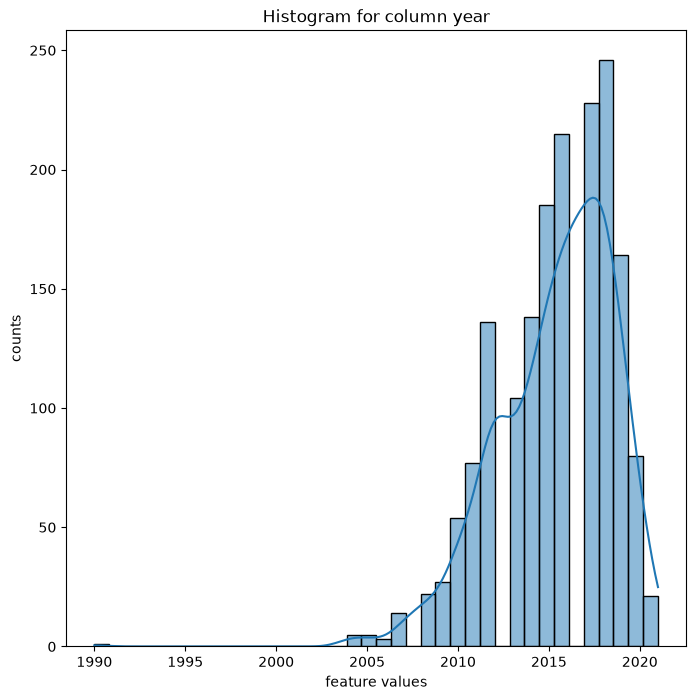

<Figure size 800x800 with 0 Axes>

<Axes: xlabel='distance_travelled(kms)', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column distance_travelled(kms)')

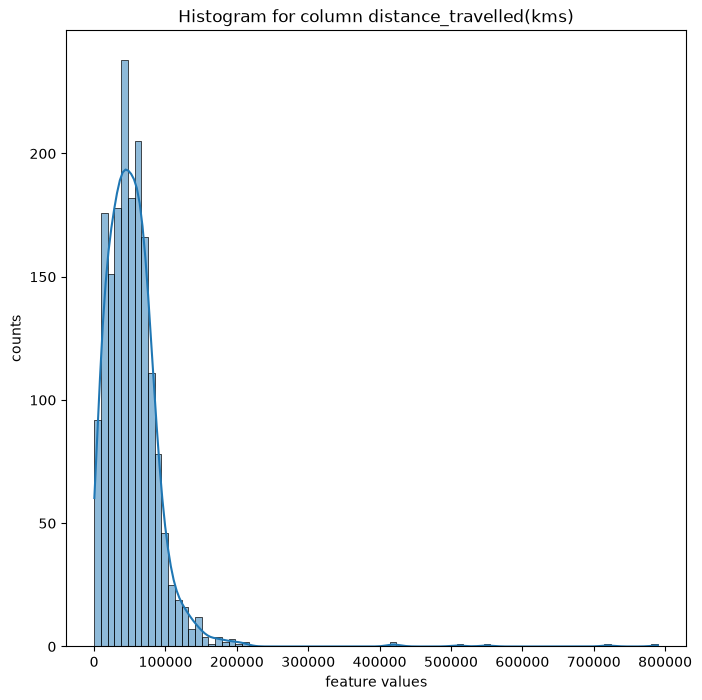

<Figure size 800x800 with 0 Axes>

<Axes: xlabel='brand_rank', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column brand_rank')

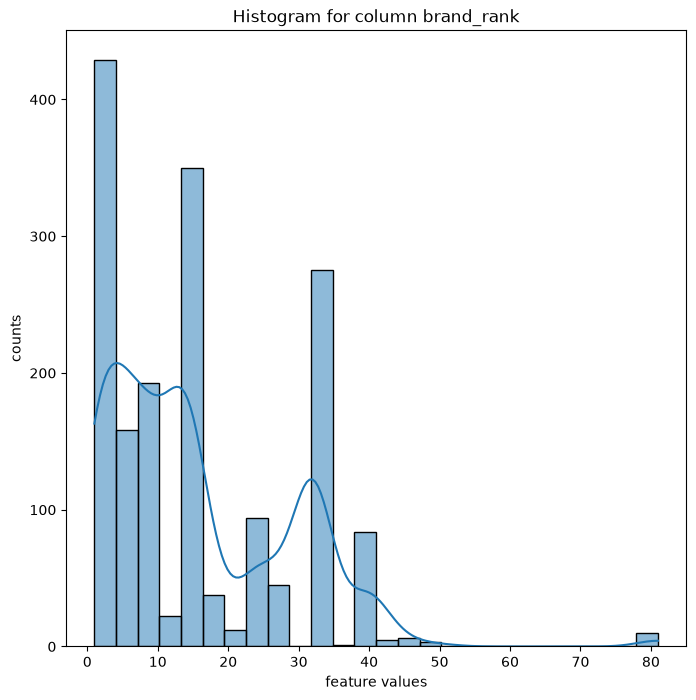

<Figure size 800x800 with 0 Axes>

<Axes: xlabel='car_age', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column car_age')

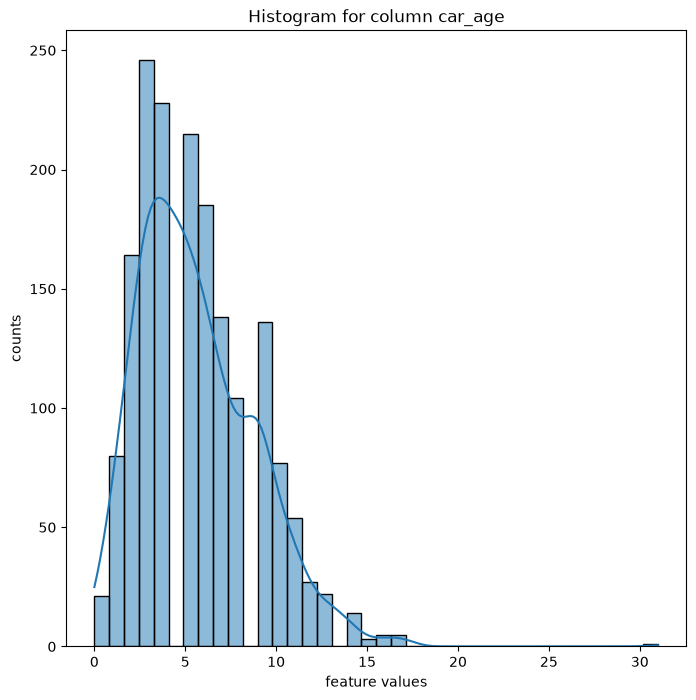

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in numeric:
    plt.figure(figsize=(8,8))
    sns.histplot(df[col],kde=True)
    plt.xlabel('feature values')
    plt.ylabel('counts')
    plt.title(f'Histogram for column {col}')
    plt.show()

# I can see skewness (right tail) in distance travelled feature. brand_rank, age and year are okay, not many outliers, also, will drop year or age

In [90]:
df[numeric].skew().sort_values()

target.skew()

year                      -0.941731
car_age                    0.941731
brand_rank                 1.192134
distance_travelled(kms)    6.854832
dtype: float64

np.float64(3.1689263313330707)